# 🛒 Coupon Prediction — E-Commerce Cart Abandonment
**Target**: `Coupon_Offered` (Binary Classification: 0 = No Coupon, 1 = Coupon)

**Models**: Logistic Regression · Random Forest · Gradient Boosting · XGBoost · LightGBM

## 0. Install Dependencies

In [1]:
# Run this cell if xgboost / lightgbm are not installed (e.g. Google Colab)
!pip install xgboost lightgbm -q

## 1. Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve, ConfusionMatrixDisplay
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb
import lightgbm as lgb

print('All libraries loaded successfully!')

All libraries loaded successfully!


## 2. Load Data

In [3]:
df = pd.read_csv('/content/Cart_Abandonment_Uplift_Dataset-ECommerce_Cart_Data.csv')
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (15000, 21)


,User_ID,Product_ID,Product_Category,Base_Price_USD,Product_Margin_Pct,Absolute_Margin_USD,Device_Type,User_Location,Session_Duration_Mins,Pages_Visited,...,Past_Purchase_Count,Historical_Coupon_Reliance_Ratio,Day_Of_Week,Is_Payday_Weekend,Coupon_Offered,Discount_Percentage,Discount_Value_USD,Net_Price_USD,Post_Discount_Profit_USD,Converted_Is_Purchased
0,USR_107270,PROD_200414,Apparel,$125.66,48.0%,$60.32,Mobile App,Latin America,11,6,...,1,27.0%,Friday,0,0,0.0%,$0.00,$125.66,$60.32,0
1,USR_107603,PROD_201376,Electronics,$377.17,22.0%,$82.98,Mobile Web,North America,35,9,...,11,38.0%,Thursday,0,0,0.0%,$0.00,$377.17,$82.98,0
2,USR_100860,PROD_201180,Electronics,$528.59,16.0%,$84.57,Mobile App,North America,13,8,...,9,14.0%,Wednesday,0,1,15.0%,$79.29,$449.30,$5.28,0
3,USR_105390,PROD_201284,Home & Kitchen,$174.78,26.0%,$45.44,Mobile App,Latin America,5,8,...,2,21.0%,Saturday,1,0,0.0%,$0.00,$174.78,$45.44,0
4,USR_105226,PROD_201100,Apparel,$120.51,58.0%,$69.90,Mobile Web,North America,15,3,...,6,24.0%,Thursday,0,1,10.0%,$12.05,$108.46,$57.85,0


In [4]:
print('Columns:', df.columns.tolist())
print('\nData Types:')
print(df.dtypes)
print('\nTarget distribution:')
print(df['Coupon_Offered'].value_counts())

Columns: ['User_ID', 'Product_ID', 'Product_Category', 'Base_Price_USD', 'Product_Margin_Pct', 'Absolute_Margin_USD', 'Device_Type', 'User_Location', 'Session_Duration_Mins', 'Pages_Visited', 'Cart_Staleness_Hours', 'Past_Purchase_Count', 'Historical_Coupon_Reliance_Ratio', 'Day_Of_Week', 'Is_Payday_Weekend', 'Coupon_Offered', 'Discount_Percentage', 'Discount_Value_USD', 'Net_Price_USD', 'Post_Discount_Profit_USD', 'Converted_Is_Purchased']

Data Types:
User_ID                             object
Product_ID                          object
Product_Category                    object
Base_Price_USD                      object
Product_Margin_Pct                  object
Absolute_Margin_USD                 object
Device_Type                         object
User_Location                       object
Session_Duration_Mins                int64
Pages_Visited                        int64
Cart_Staleness_Hours                 int64
Past_Purchase_Count                  int64
Historical_Coupon_Reliance

## 3. Data Cleaning

In [5]:
# --- Clean dollar columns ---
dollar_cols = ['Base_Price_USD', 'Absolute_Margin_USD', 'Discount_Value_USD',
               'Net_Price_USD', 'Post_Discount_Profit_USD']

for col in dollar_cols:
    df[col] = df[col].astype(str).str.replace('$', '', regex=False)
    df[col] = df[col].astype(str).str.replace(',', '', regex=False)
    df[col] = pd.to_numeric(df[col], errors='coerce')

# --- Clean percentage columns ---
pct_cols = ['Product_Margin_Pct', 'Historical_Coupon_Reliance_Ratio', 'Discount_Percentage']

for col in pct_cols:
    df[col] = df[col].astype(str).str.replace('%', '', regex=False)
    df[col] = df[col].astype(str).str.replace(',', '', regex=False)
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Cleaned dollar and percentage columns.')
df.head()

Cleaned dollar and percentage columns.


,User_ID,Product_ID,Product_Category,Base_Price_USD,Product_Margin_Pct,Absolute_Margin_USD,Device_Type,User_Location,Session_Duration_Mins,Pages_Visited,...,Past_Purchase_Count,Historical_Coupon_Reliance_Ratio,Day_Of_Week,Is_Payday_Weekend,Coupon_Offered,Discount_Percentage,Discount_Value_USD,Net_Price_USD,Post_Discount_Profit_USD,Converted_Is_Purchased
0,USR_107270,PROD_200414,Apparel,125.66,48.0,60.32,Mobile App,Latin America,11,6,...,1,27.0,Friday,0,0,0.0,0.00,125.66,60.32,0
1,USR_107603,PROD_201376,Electronics,377.17,22.0,82.98,Mobile Web,North America,35,9,...,11,38.0,Thursday,0,0,0.0,0.00,377.17,82.98,0
2,USR_100860,PROD_201180,Electronics,528.59,16.0,84.57,Mobile App,North America,13,8,...,9,14.0,Wednesday,0,1,15.0,79.29,449.30,5.28,0
3,USR_105390,PROD_201284,Home & Kitchen,174.78,26.0,45.44,Mobile App,Latin America,5,8,...,2,21.0,Saturday,1,0,0.0,0.00,174.78,45.44,0
4,USR_105226,PROD_201100,Apparel,120.51,58.0,69.90,Mobile Web,North America,15,3,...,6,24.0,Thursday,0,1,10.0,12.05,108.46,57.85,0


In [6]:
# Check missing values
print('Missing values:')
print(df.isnull().sum()[df.isnull().sum() > 0])

# Fill any remaining numeric NaNs with median
for col in df.select_dtypes(include='number').columns:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].median(), inplace=True)

print('\nAfter fill — remaining NaNs:', df.isnull().sum().sum())

Missing values:
Series([], dtype: int64)

After fill — remaining NaNs: 0


## 4. Exploratory Data Analysis

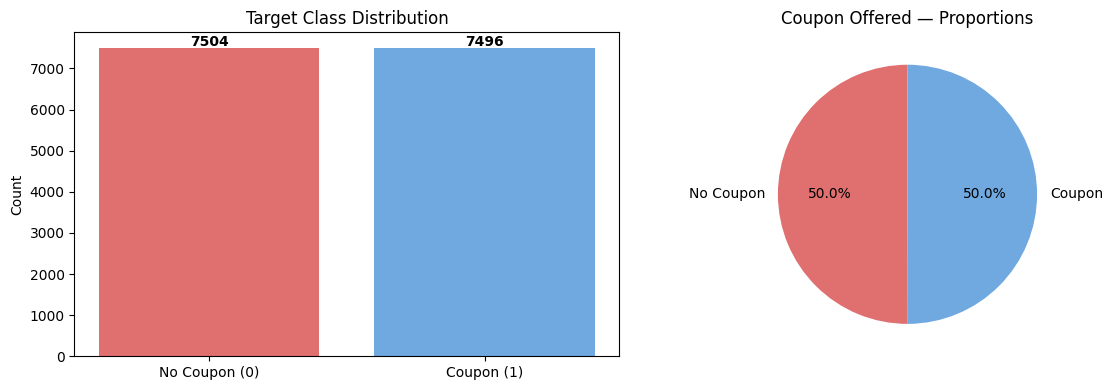

In [7]:
# Target class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df['Coupon_Offered'].value_counts()
axes[0].bar(['No Coupon (0)', 'Coupon (1)'], counts.values, color=['#E07070', '#70A8E0'])
axes[0].set_title('Target Class Distribution')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

axes[1].pie(counts.values, labels=['No Coupon', 'Coupon'], autopct='%1.1f%%',
            colors=['#E07070', '#70A8E0'], startangle=90)
axes[1].set_title('Coupon Offered — Proportions')
plt.tight_layout()
plt.show()

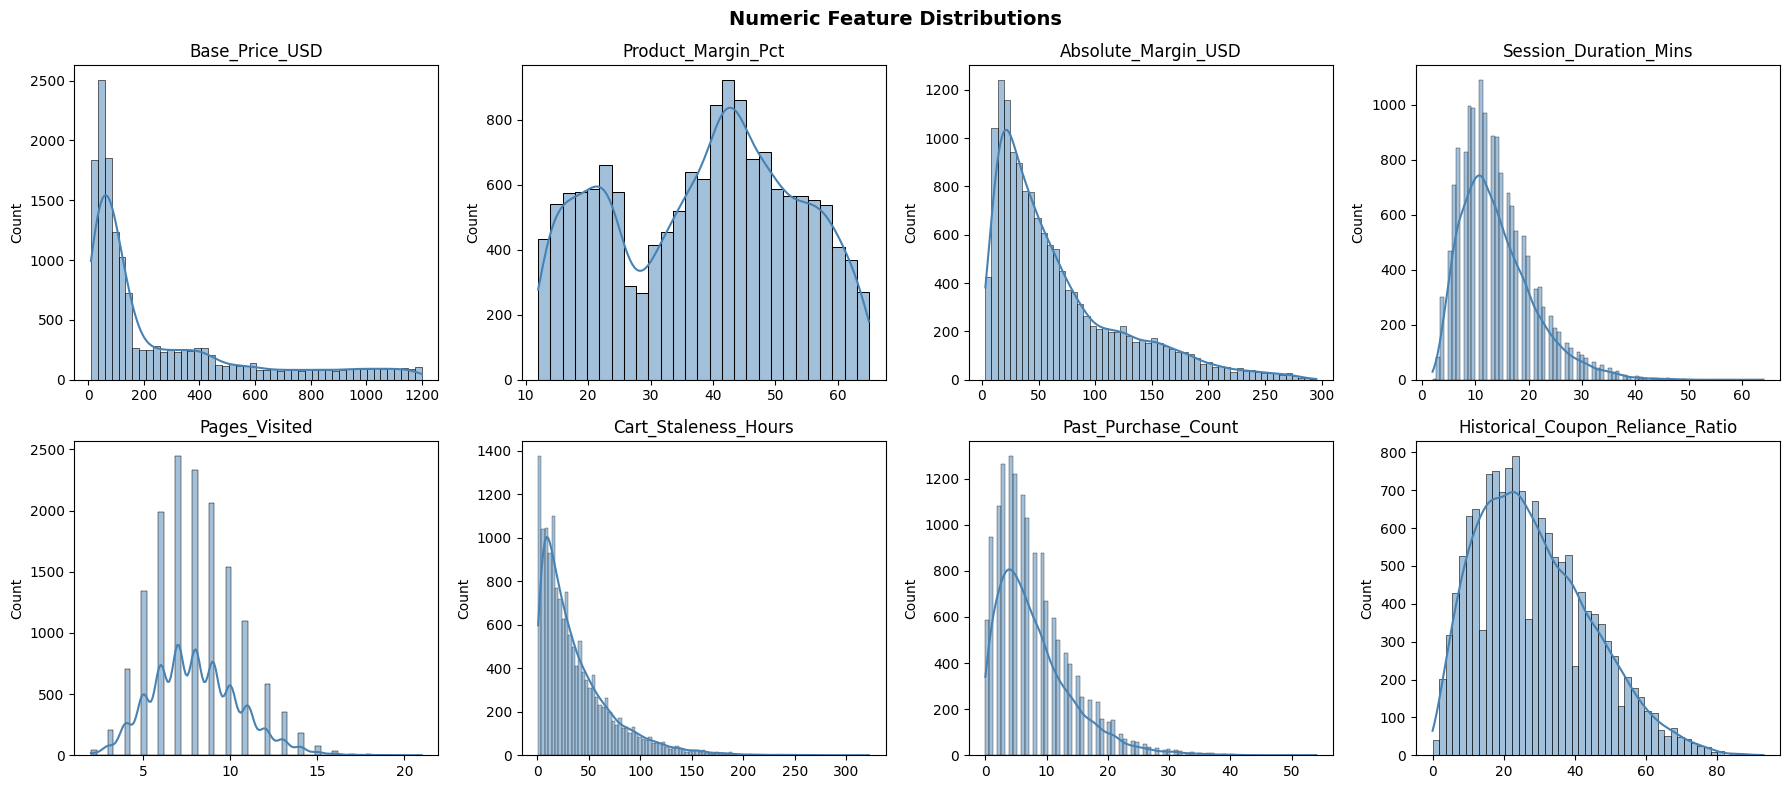

In [8]:
# Numeric feature distributions
num_cols = ['Base_Price_USD', 'Product_Margin_Pct', 'Absolute_Margin_USD',
            'Session_Duration_Mins', 'Pages_Visited', 'Cart_Staleness_Hours',
            'Past_Purchase_Count', 'Historical_Coupon_Reliance_Ratio']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(x=df[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('')
plt.suptitle('Numeric Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

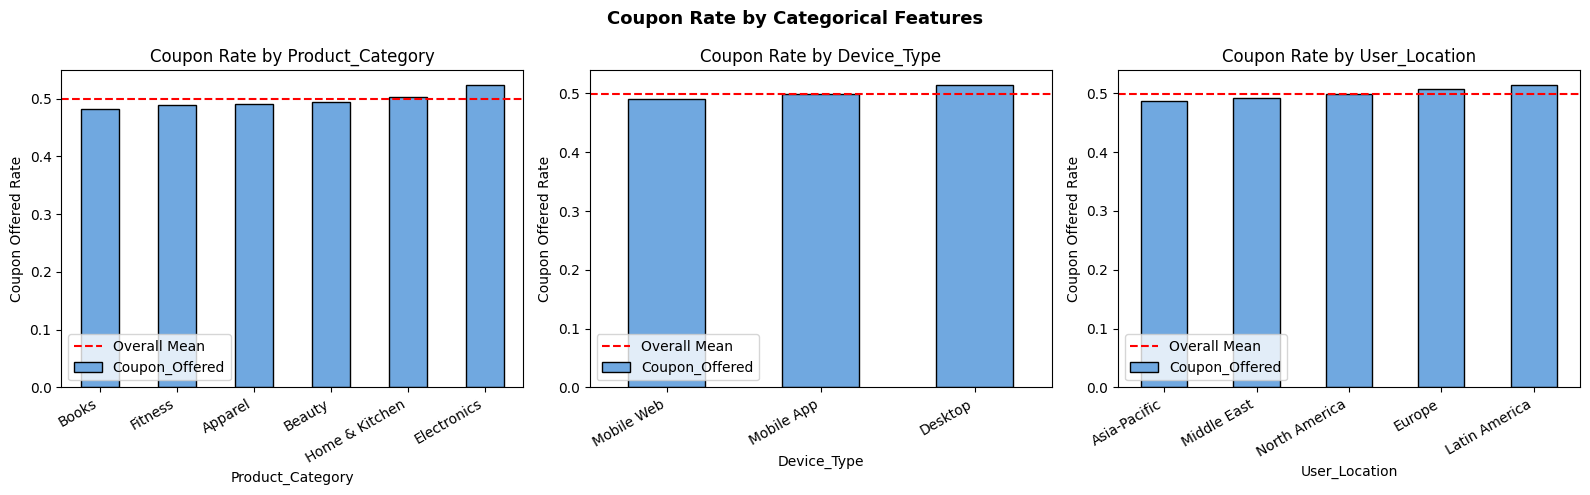

In [9]:
# Categorical feature vs Coupon_Offered
cat_cols = ['Product_Category', 'Device_Type', 'User_Location']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, col in enumerate(cat_cols):
    ct = df.groupby(col)['Coupon_Offered'].mean().sort_values()
    ct.plot(kind='bar', ax=axes[i], color='#70A8E0', edgecolor='black')
    axes[i].set_title(f'Coupon Rate by {col}')
    axes[i].set_ylabel('Coupon Offered Rate')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30, ha='right')
    axes[i].axhline(df['Coupon_Offered'].mean(), color='red', linestyle='--', label='Overall Mean')
    axes[i].legend()
plt.suptitle('Coupon Rate by Categorical Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

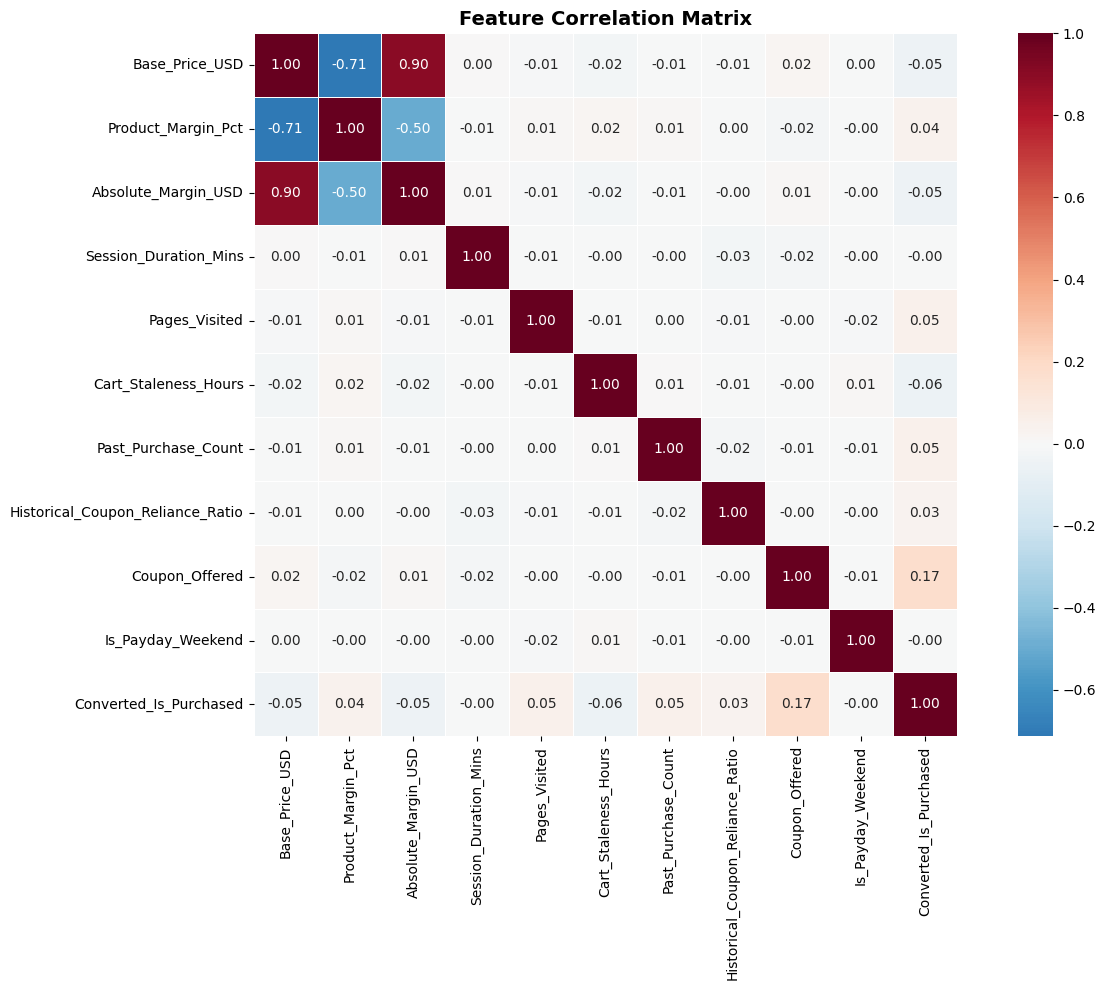

In [10]:
# Correlation heatmap
plt.figure(figsize=(14, 10))
corr_df = df[num_cols + ['Coupon_Offered', 'Is_Payday_Weekend', 'Converted_Is_Purchased']]
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Feature Engineering & Preprocessing

In [11]:
# Drop non-predictive ID columns and Day_Of_Week (dropped in original notebook)
df_model = df.drop(columns=['User_ID', 'Product_ID', 'Day_Of_Week'], errors='ignore').copy()

# One-hot encode remaining categorical columns
cat_encode = ['Product_Category', 'Device_Type', 'User_Location']
df_model = pd.get_dummies(df_model, columns=cat_encode, drop_first=False, dtype=int)

print('Shape after encoding:', df_model.shape)
print('Columns:', df_model.columns.tolist())

Shape after encoding: (15000, 29)
Columns: ['Base_Price_USD', 'Product_Margin_Pct', 'Absolute_Margin_USD', 'Session_Duration_Mins', 'Pages_Visited', 'Cart_Staleness_Hours', 'Past_Purchase_Count', 'Historical_Coupon_Reliance_Ratio', 'Is_Payday_Weekend', 'Coupon_Offered', 'Discount_Percentage', 'Discount_Value_USD', 'Net_Price_USD', 'Post_Discount_Profit_USD', 'Converted_Is_Purchased', 'Product_Category_Apparel', 'Product_Category_Beauty', 'Product_Category_Books', 'Product_Category_Electronics', 'Product_Category_Fitness', 'Product_Category_Home & Kitchen', 'Device_Type_Desktop', 'Device_Type_Mobile App', 'Device_Type_Mobile Web', 'User_Location_Asia-Pacific', 'User_Location_Europe', 'User_Location_Latin America', 'User_Location_Middle East', 'User_Location_North America']


In [12]:
# Define features and target
TARGET = 'Coupon_Offered'
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

print(f'Features: {X.shape[1]}')
print(f'Samples : {X.shape[0]}')
print(f'Target  : {y.value_counts().to_dict()}')

Features: 28
Samples : 15000
Target  : {0: 7504, 1: 7496}


In [13]:
# Train / Test split — stratified to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')
print(f'Train target dist: {y_train.value_counts().to_dict()}')
print(f'Test  target dist: {y_test.value_counts().to_dict()}')

Train: (12000, 28)  |  Test: (3000, 28)
Train target dist: {0: 6003, 1: 5997}
Test  target dist: {0: 1501, 1: 1499}


In [14]:
# Scale features — fit on train, transform both (prevents data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('Scaling complete.')
print(f'  X_train_scaled mean ≈ {X_train_scaled.mean():.4f}  std ≈ {X_train_scaled.std():.4f}')
print(f'  X_test_scaled  mean ≈ {X_test_scaled.mean():.4f}  std ≈ {X_test_scaled.std():.4f}')

Scaling complete.
  X_train_scaled mean ≈ 0.0000  std ≈ 1.0000
  X_test_scaled  mean ≈ 0.0018  std ≈ 1.0067


## 6. Model Training

In [15]:
# ── Helper to evaluate any trained model ──────────────────────────────────────
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, scaled=True):
    """Train model, evaluate on test set, return metrics dict."""
    model.fit(X_tr, y_tr)
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    metrics = {
        'Model'    : name,
        'Accuracy' : accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall'   : recall_score(y_te, y_pred, zero_division=0),
        'F1'       : f1_score(y_te, y_pred, zero_division=0),
        'ROC-AUC'  : roc_auc_score(y_te, y_proba),
    }
    return metrics, model, y_pred, y_proba

results   = []
models    = {}
all_preds = {}

### 6.1 Logistic Regression

In [16]:
lr = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
m, models['LR'], all_preds['LR_pred'], all_preds['LR_proba'] = evaluate_model(
    'Logistic Regression', lr, X_train_scaled, y_train, X_test_scaled, y_test
)
results.append(m)
print(f"Logistic Regression  →  Acc: {m['Accuracy']:.4f}  |  AUC: {m['ROC-AUC']:.4f}")

Logistic Regression  →  Acc: 1.0000  |  AUC: 1.0000


### 6.2 Random Forest

In [17]:
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
# Tree-based models work on raw (unscaled) features
m, models['RF'], all_preds['RF_pred'], all_preds['RF_proba'] = evaluate_model(
    'Random Forest', rf, X_train, y_train, X_test, y_test
)
results.append(m)
print(f"Random Forest        →  Acc: {m['Accuracy']:.4f}  |  AUC: {m['ROC-AUC']:.4f}")

Random Forest        →  Acc: 1.0000  |  AUC: 1.0000


### 6.3 Gradient Boosting

In [18]:
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                 max_depth=5, random_state=42)
m, models['GB'], all_preds['GB_pred'], all_preds['GB_proba'] = evaluate_model(
    'Gradient Boosting', gb, X_train, y_train, X_test, y_test
)
results.append(m)
print(f"Gradient Boosting    →  Acc: {m['Accuracy']:.4f}  |  AUC: {m['ROC-AUC']:.4f}")

Gradient Boosting    →  Acc: 1.0000  |  AUC: 1.0000


### 6.4 XGBoost

In [19]:
xgbc = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)
m, models['XGB'], all_preds['XGB_pred'], all_preds['XGB_proba'] = evaluate_model(
    'XGBoost', xgbc, X_train, y_train, X_test, y_test
)
results.append(m)
print(f"XGBoost              →  Acc: {m['Accuracy']:.4f}  |  AUC: {m['ROC-AUC']:.4f}")

XGBoost              →  Acc: 1.0000  |  AUC: 1.0000


### 6.5 LightGBM

In [20]:
lgbc = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    verbose=-1
)
m, models['LGBM'], all_preds['LGBM_pred'], all_preds['LGBM_proba'] = evaluate_model(
    'LightGBM', lgbc, X_train, y_train, X_test, y_test
)
results.append(m)
print(f"LightGBM             →  Acc: {m['Accuracy']:.4f}  |  AUC: {m['ROC-AUC']:.4f}")

LightGBM             →  Acc: 1.0000  |  AUC: 1.0000


## 7. Results Comparison

In [21]:
results_df = pd.DataFrame(results).set_index('Model')
results_df = results_df.sort_values('ROC-AUC', ascending=False)
print('=' * 65)
print(results_df.round(4).to_string())
print('=' * 65)

                     Accuracy  Precision  Recall   F1  ROC-AUC
Model                                                         
Logistic Regression       1.0        1.0     1.0  1.0      1.0
Random Forest             1.0        1.0     1.0  1.0      1.0
Gradient Boosting         1.0        1.0     1.0  1.0      1.0
XGBoost                   1.0        1.0     1.0  1.0      1.0
LightGBM                  1.0        1.0     1.0  1.0      1.0


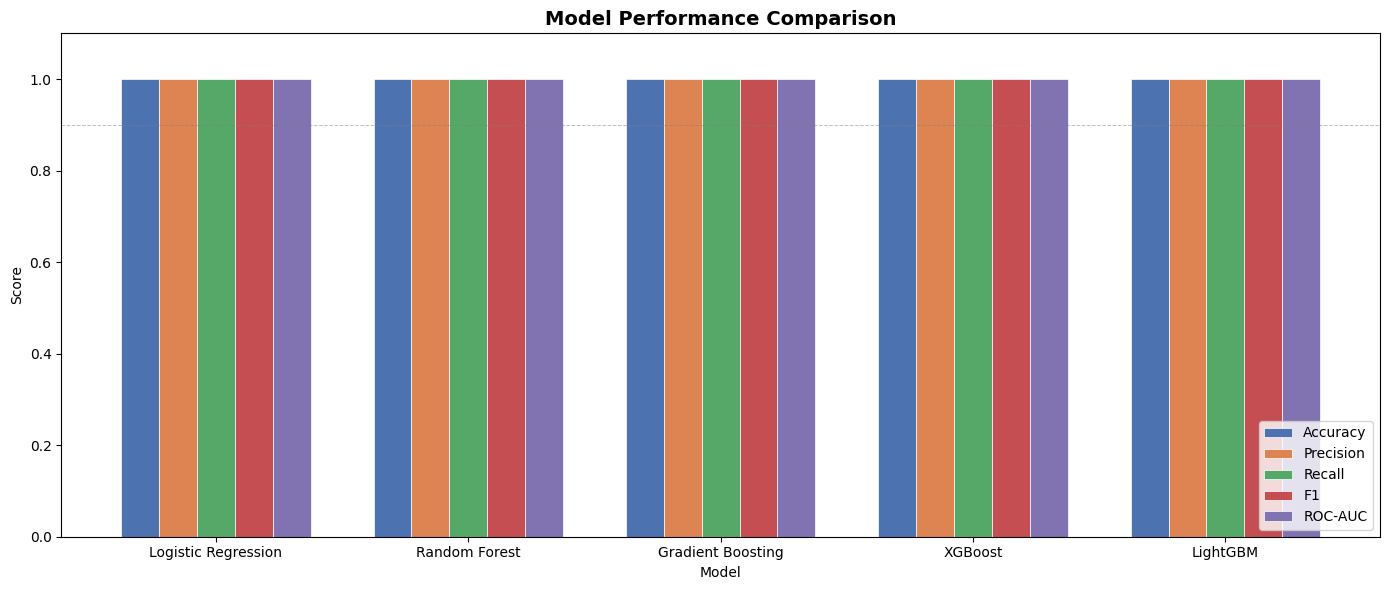

In [22]:
# Bar chart comparison
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
x = np.arange(len(results_df))
width = 0.15
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2']

fig, ax = plt.subplots(figsize=(14, 6))
for i, (metric, color) in enumerate(zip(metrics_to_plot, colors)):
    bars = ax.bar(x + i * width, results_df[metric], width,
                  label=metric, color=color, edgecolor='white', linewidth=0.5)

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x + width * 2)
ax.set_xticklabels(results_df.index, fontsize=10)
ax.set_ylim(0, 1.1)
ax.legend(loc='lower right')
ax.axhline(0.9, color='grey', linestyle='--', linewidth=0.7, alpha=0.5)
plt.tight_layout()
plt.show()

## 8. Confusion Matrices

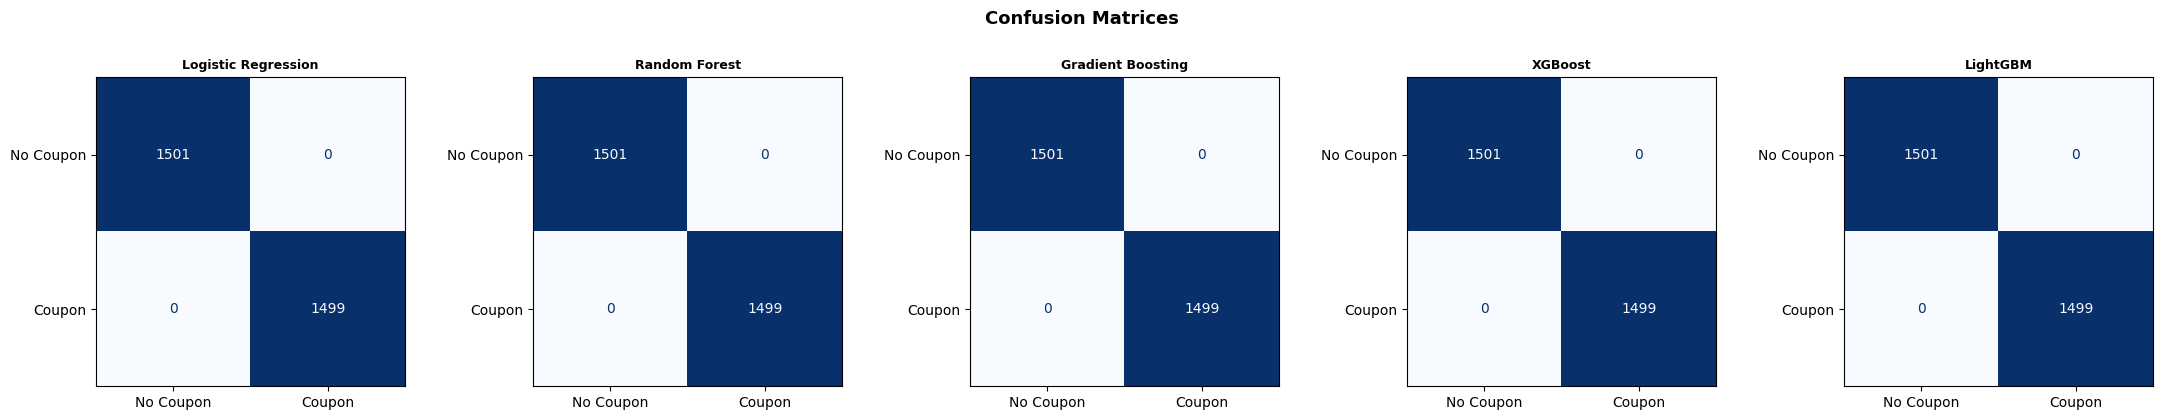

In [23]:
model_names  = ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'LightGBM']
model_keys   = ['LR', 'RF', 'GB', 'XGB', 'LGBM']

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, key, name in zip(axes, model_keys, model_names):
    cm = confusion_matrix(y_test, all_preds[f'{key}_pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Coupon', 'Coupon'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.suptitle('Confusion Matrices', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 9. ROC Curves

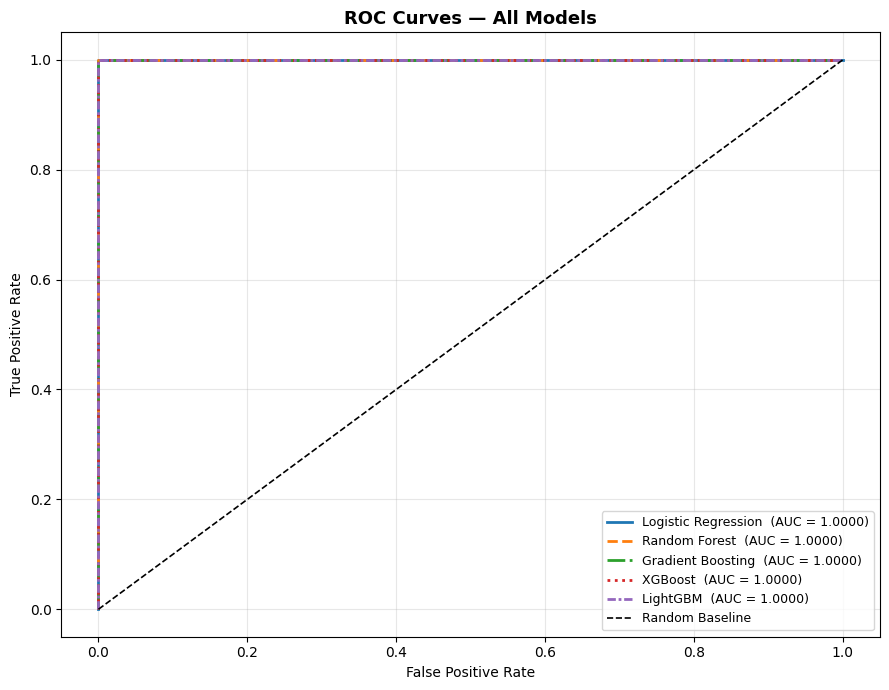

In [24]:
plt.figure(figsize=(9, 7))
line_styles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1))]
for key, name, ls in zip(model_keys, model_names, line_styles):
    fpr, tpr, _ = roc_curve(y_test, all_preds[f'{key}_proba'])
    auc = roc_auc_score(y_test, all_preds[f'{key}_proba'])
    plt.plot(fpr, tpr, linestyle=ls, lw=2, label=f'{name}  (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All Models', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Feature Importance

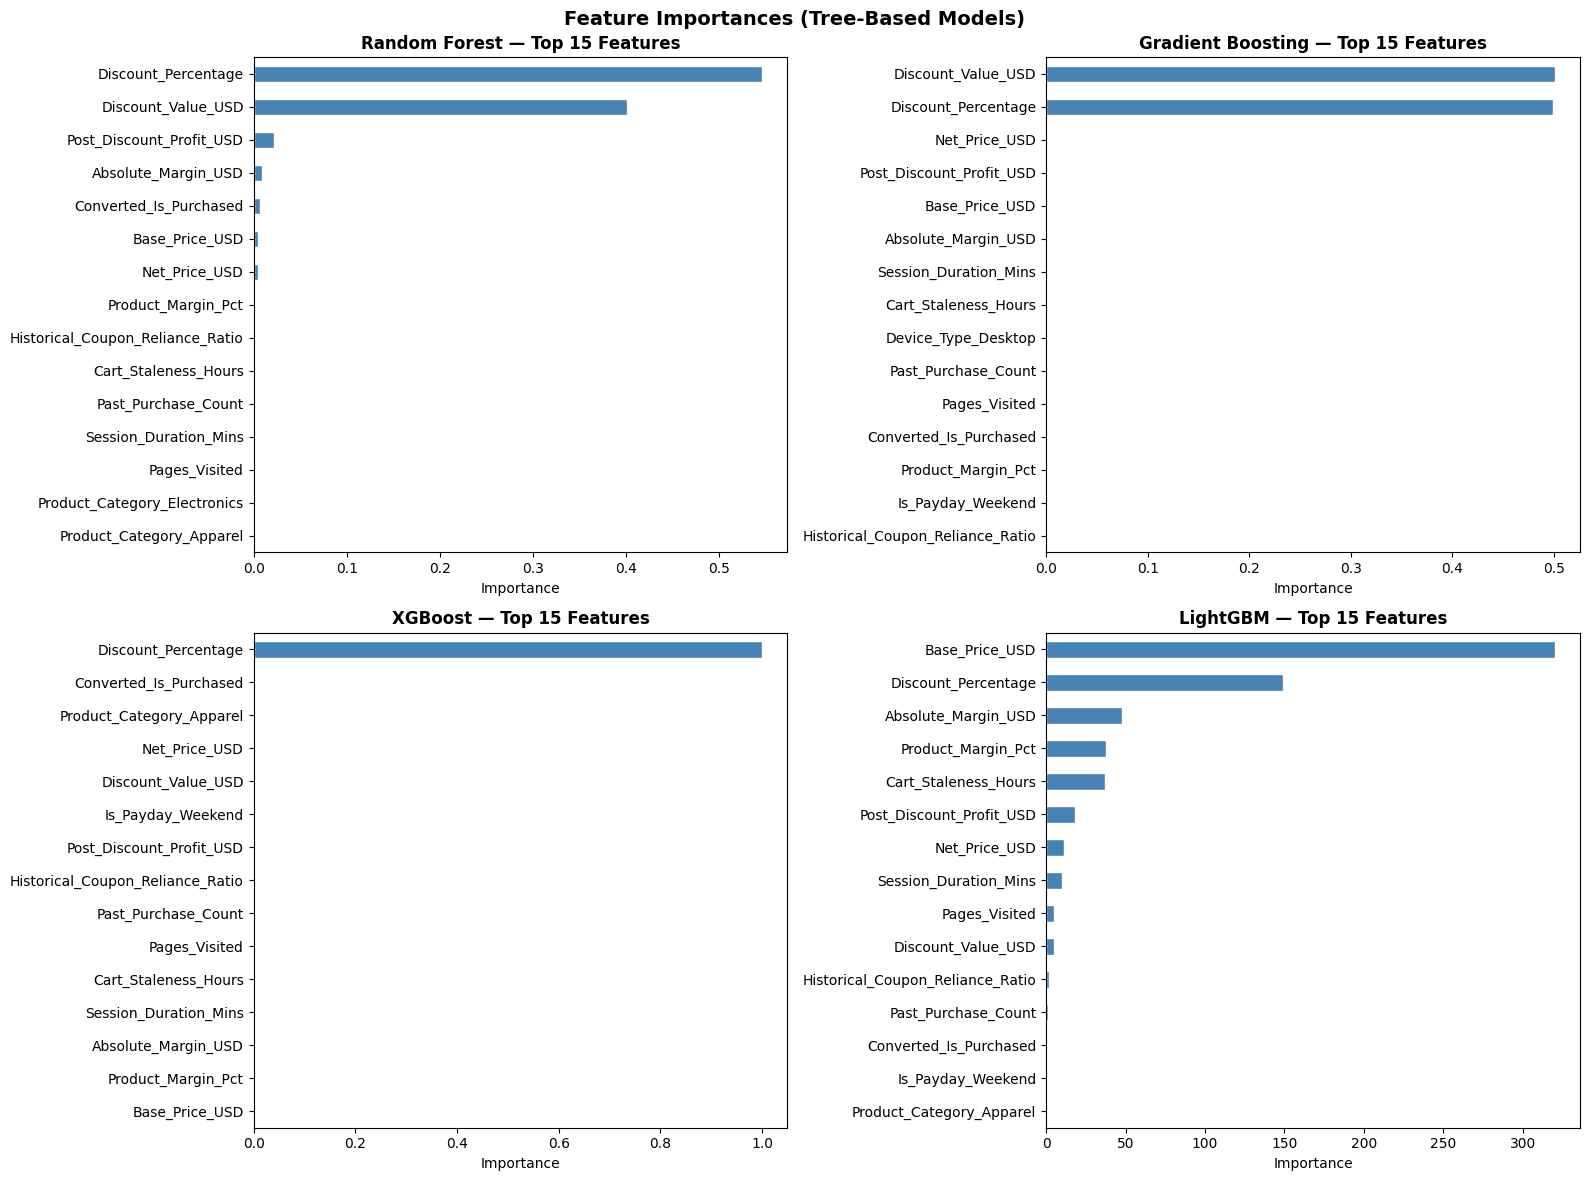

In [25]:
feature_names = X.columns.tolist()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

tree_models = [
    ('Random Forest',    models['RF'],   'RF'),
    ('Gradient Boosting',models['GB'],   'GB'),
    ('XGBoost',          models['XGB'],  'XGB'),
    ('LightGBM',         models['LGBM'], 'LGBM'),
]

for ax, (name, model, key) in zip(axes, tree_models):
    importances = pd.Series(model.feature_importances_, index=feature_names)
    top15 = importances.nlargest(15).sort_values()
    top15.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(f'{name} — Top 15 Features', fontweight='bold')
    ax.set_xlabel('Importance')

plt.suptitle('Feature Importances (Tree-Based Models)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

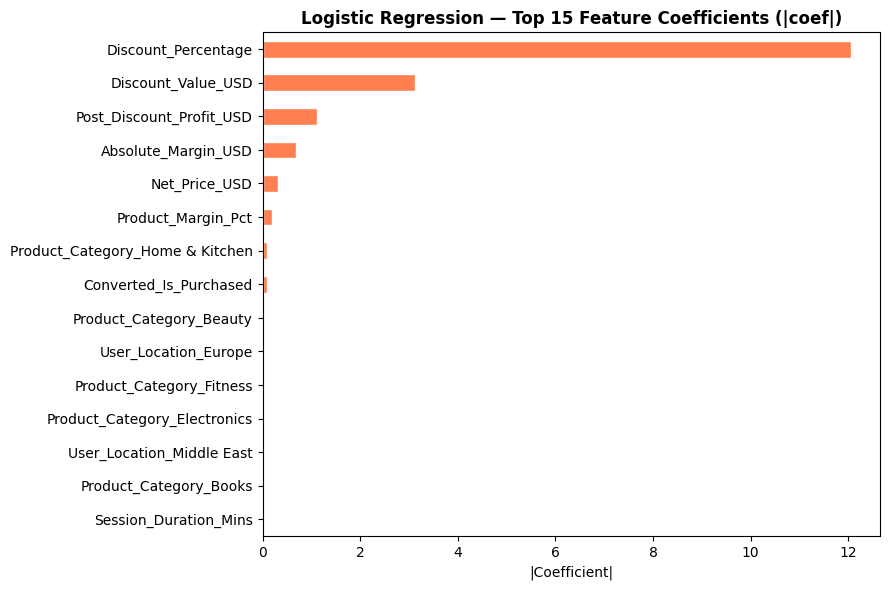

In [26]:
# Logistic Regression — coefficient magnitudes
lr_coef = pd.Series(np.abs(models['LR'].coef_[0]), index=feature_names)
top15_lr = lr_coef.nlargest(15).sort_values()

plt.figure(figsize=(9, 6))
top15_lr.plot(kind='barh', color='coral', edgecolor='white')
plt.title('Logistic Regression — Top 15 Feature Coefficients (|coef|)', fontweight='bold')
plt.xlabel('|Coefficient|')
plt.tight_layout()
plt.show()

## 11. Cross-Validation (5-Fold)

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = [
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42), X_train_scaled),
    ('Random Forest',       RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train),
    ('Gradient Boosting',   GradientBoostingClassifier(n_estimators=100, random_state=42), X_train),
    ('XGBoost',             xgb.XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42), X_train),
    ('LightGBM',            lgb.LGBMClassifier(n_estimators=100, random_state=42, verbose=-1), X_train),
]

cv_results = []
for name, model, X_cv in cv_models:
    scores = cross_val_score(model, X_cv, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_results.append({'Model': name, 'CV AUC Mean': scores.mean(), 'CV AUC Std': scores.std()})
    print(f'{name:25s}  CV AUC = {scores.mean():.4f} ± {scores.std():.4f}')

cv_df = pd.DataFrame(cv_results).set_index('Model')
print('\n', cv_df.round(4))

Logistic Regression        CV AUC = 1.0000 ± 0.0000
Random Forest              CV AUC = 1.0000 ± 0.0000
Gradient Boosting          CV AUC = 1.0000 ± 0.0000
XGBoost                    CV AUC = 1.0000 ± 0.0000
LightGBM                   CV AUC = 1.0000 ± 0.0000

                      CV AUC Mean  CV AUC Std
Model                                       
Logistic Regression          1.0         0.0
Random Forest                1.0         0.0
Gradient Boosting            1.0         0.0
XGBoost                      1.0         0.0
LightGBM                     1.0         0.0


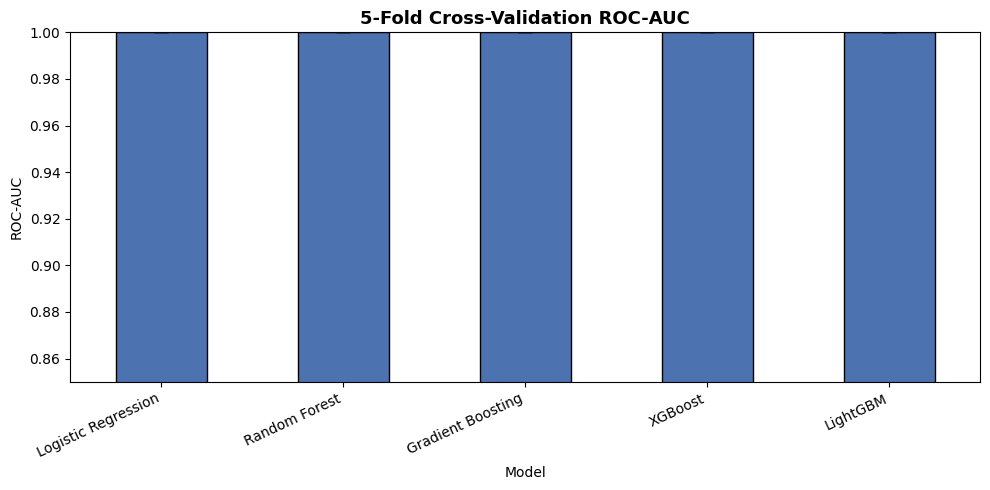

In [28]:
# Plot CV results
fig, ax = plt.subplots(figsize=(10, 5))
cv_df['CV AUC Mean'].plot(kind='bar', ax=ax, color='#4C72B0', edgecolor='black',
                           yerr=cv_df['CV AUC Std'], capsize=5)
ax.set_title('5-Fold Cross-Validation ROC-AUC', fontweight='bold', fontsize=13)
ax.set_ylabel('ROC-AUC')
ax.set_ylim(0.85, 1.0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 12. Classification Reports

In [29]:
for key, name in zip(model_keys, model_names):
    print(f'\n{"=" * 55}')
    print(f'  {name}')
    print(f'{"=" * 55}')
    print(classification_report(y_test, all_preds[f'{key}_pred'],
                                 target_names=['No Coupon', 'Coupon']))


  Logistic Regression
              precision    recall  f1-score   support

   No Coupon       1.00      1.00      1.00      1501
      Coupon       1.00      1.00      1.00      1499

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000


  Random Forest
              precision    recall  f1-score   support

   No Coupon       1.00      1.00      1.00      1501
      Coupon       1.00      1.00      1.00      1499

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000


  Gradient Boosting
              precision    recall  f1-score   support

   No Coupon       1.00      1.00      1.00      1501
      Coupon       1.00      1.00      1.00      1499

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg 

## 13. Best Model Summary

In [30]:
best_row = results_df.iloc[0]
print(f'\n🏆 Best Model by ROC-AUC: {best_row.name}')
print(f'   Accuracy  : {best_row["Accuracy"]:.4f}')
print(f'   Precision : {best_row["Precision"]:.4f}')
print(f'   Recall    : {best_row["Recall"]:.4f}')
print(f'   F1        : {best_row["F1"]:.4f}')
print(f'   ROC-AUC   : {best_row["ROC-AUC"]:.4f}')
print('\nFull Leaderboard:')
print(results_df.round(4))


🏆 Best Model by ROC-AUC: Logistic Regression
   Accuracy  : 1.0000
   Precision : 1.0000
   Recall    : 1.0000
   F1        : 1.0000
   ROC-AUC   : 1.0000

Full Leaderboard:
                     Accuracy  Precision  Recall   F1  ROC-AUC
Model                                                         
Logistic Regression       1.0        1.0     1.0  1.0      1.0
Random Forest             1.0        1.0     1.0  1.0      1.0
Gradient Boosting         1.0        1.0     1.0  1.0      1.0
XGBoost                   1.0        1.0     1.0  1.0      1.0
LightGBM                  1.0        1.0     1.0  1.0      1.0


In [31]:

import joblib
from pathlib import Path

# Get the already-trained LightGBM model
trained_model = models['LGBM']

# Check that it is fitted
print("Model type:", type(trained_model))
print("Fitted:", hasattr(trained_model, "n_features_in_"))

# Save model and feature names together
project_dir = Path.cwd()
model_dir = project_dir / "model"
model_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model": trained_model,
    "feature_names": X.columns.tolist()
}

model_path = model_dir / "cartwhisperer_model.pkl"
joblib.dump(model_bundle, model_path)

print(f"Saved trained model to: {model_path}")
print("Number of features:", len(X.columns))
print("Feature names:", X.columns.tolist())


Model type: <class 'lightgbm.sklearn.LGBMClassifier'>
Fitted: True
Saved trained model to: /content/model/cartwhisperer_model.pkl
Number of features: 28
Feature names: ['Base_Price_USD', 'Product_Margin_Pct', 'Absolute_Margin_USD', 'Session_Duration_Mins', 'Pages_Visited', 'Cart_Staleness_Hours', 'Past_Purchase_Count', 'Historical_Coupon_Reliance_Ratio', 'Is_Payday_Weekend', 'Discount_Percentage', 'Discount_Value_USD', 'Net_Price_USD', 'Post_Discount_Profit_USD', 'Converted_Is_Purchased', 'Product_Category_Apparel', 'Product_Category_Beauty', 'Product_Category_Books', 'Product_Category_Electronics', 'Product_Category_Fitness', 'Product_Category_Home & Kitchen', 'Device_Type_Desktop', 'Device_Type_Mobile App', 'Device_Type_Mobile Web', 'User_Location_Asia-Pacific', 'User_Location_Europe', 'User_Location_Latin America', 'User_Location_Middle East', 'User_Location_North America']


In [32]:
from google.colab import files

files.download("/content/model/cartwhisperer_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>